# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Make the noise

In [2]:
rng = np.random.default_rng(0)
X = rng.normal(size=(100, 5000))
y = rng.integers(0, 2, 100)
print(X.shape, y[:10])

(100, 5000) [1 0 0 1 1 1 1 1 0 1]


# The Leaky Way

In [3]:
X_sel = SelectKBest(f_classif, k=20).fit_transform(X, y)
X_tr, X_te, y_tr, y_te = train_test_split(X_sel, y, random_state=0)
leaky = LogisticRegression().fit(X_tr, y_tr).score(X_te, y_te)
print("Leaky:", leaky)

Leaky: 0.76


# The Honest Way

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, random_state=0)
sel = SelectKBest(f_classif, k=20).fit(X_tr, y_tr)
model = LogisticRegression().fit(sel.transform(X_tr), y_tr)
honest = model.score(sel.transform(X_te), y_te)
print("Honest:", honest)

Honest: 0.6


# 30 seeds

In [5]:
def run(seed):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(100, 5000))
    y = rng.integers(0, 2, 100)

    X_sel = SelectKBest(f_classif, k=20).fit_transform(X, y)
    a, b, c, d = train_test_split(X_sel, y, random_state=seed)
    leaky = LogisticRegression().fit(a, c).score(b, d)

    a, b, c, d = train_test_split(X, y, random_state=seed)
    sel = SelectKBest(f_classif, k=20).fit(a, c)
    honest = LogisticRegression().fit(sel.transform(a), c).score(sel.transform(b), d)
    return leaky, honest

results = np.array([run(s) for s in range(30)])
print("Leaky avg:", results[:, 0].mean())
print("Honest avg:", results[:, 1].mean())

Leaky avg: 0.8773333333333333
Honest avg: 0.5053333333333333


# Plot

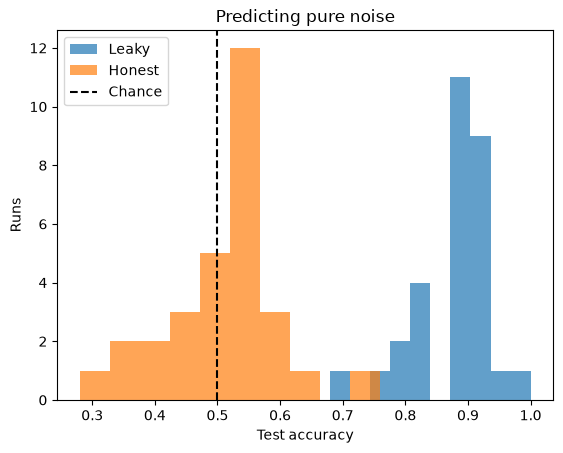

In [6]:
plt.hist(results[:, 0], alpha=0.7, label="Leaky", bins=10)
plt.hist(results[:, 1], alpha=0.7, label="Honest", bins=10)
plt.axvline(0.5, color="black", linestyle="--", label="Chance")
plt.xlabel("Test accuracy")
plt.ylabel("Runs")
plt.title("Predicting pure noise")
plt.legend()
plt.savefig("predicting_pure_noise.png", dpi=300, bbox_inches="tight")
plt.show()

# Pipeline Version

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

pipe = Pipeline([
    ("select", SelectKBest(f_classif, k=20)),
    ("clf", LogisticRegression()),
])
print("Pipeline CV:", cross_val_score(pipe, X, y, cv=5).mean())

Pipeline CV: 0.48
